In [6]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np
import json
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# =====================================================================
# 1. PREPARACIÓN DE DATOS (Data Preparation)
# =====================================================================

In [7]:
# Definimos los parámetros base según el dataset
TAMANO_IMG = (150, 150) # Resolución exigida por los datos[cite: 9, 12]
BATCH_SIZE = 32

# Cargamos el conjunto de entrenamiento desde la carpeta 'seg_train'[cite: 11]
# Reservamos un 20% para validación interna durante el entrenamiento
train_ds = tf.keras.utils.image_dataset_from_directory(
    'seg_train/seg_train',
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=TAMANO_IMG,
    batch_size=BATCH_SIZE
)

# Cargamos el conjunto de validación (el otro 20% de seg_train)
val_ds = tf.keras.utils.image_dataset_from_directory(
    'seg_train/seg_train',
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=TAMANO_IMG,
    batch_size=BATCH_SIZE
)

# Cargamos el conjunto de prueba puro desde la carpeta 'seg_test'[cite: 11]
test_ds = tf.keras.utils.image_dataset_from_directory(
    'seg_test/seg_test',
    image_size=TAMANO_IMG,
    batch_size=BATCH_SIZE,
    shuffle=False # No mezclar para mantener el orden al evaluar
)

# Guardamos los nombres de las clases (buildings, forest, etc.) para exportarlos después[cite: 2]
clases = train_ds.class_names
print("Clases detectadas:", clases)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.
Clases detectadas: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


# =====================================================================
# 2. DATA AUGMENTATION (Aumento de Datos)
# =====================================================================

In [8]:
# Creamos capas de aumento de datos que vivirán DENTRO del modelo.
# Esto previene el sobreajuste generando variaciones de las imágenes en cada época[cite: 9, 2].
data_augmentation = keras.Sequential([
  layers.RandomFlip("horizontal"),
  layers.RandomRotation(0.1),
  layers.RandomZoom(0.1),
  layers.RandomContrast(0.2), # <--- Nueva línea agregada
], name="data_augmentation")

# =====================================================================
# 3. CONSTRUCCIÓN DEL MODELO (Transfer Learning)
# =====================================================================

In [9]:
# Instanciamos EfficientNetB0 preentrenado. 'include_top=False' quita la capa final original.
# EfficientNet ya incluye su propia normalización (0-255), por lo que no dividimos por 255[cite: 2].
base_model = keras.applications.EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(150, 150, 3)
)
# Congelamos el modelo base para no dañar los pesos preentrenados (Feature Extraction)
base_model.trainable = False

# Ensamblamos el modelo final
inputs = keras.Input(shape=(150, 150, 3))
x = data_augmentation(inputs)       # 1. Aplicamos Data Augmentation
x = base_model(x, training=False)   # 2. Pasamos por EfficientNet (en modo inferencia)
x = layers.GlobalAveragePooling2D()(x) # 3. Convertimos los mapas de características a un vector 1D
x = layers.Dropout(0.3)(x)          # 4. Regularización Dropout para apagar 30% de neuronas y evitar sobreajuste[cite: 9]
outputs = layers.Dense(6, activation='softmax')(x) # 5. Capa de salida con 6 neuronas (una por clase)[cite: 9, 12]

modelo = keras.Model(inputs, outputs)

# Compilamos el modelo
# Optimizador Adam, función de pérdida para etiquetas enteras (sparse) y métrica de Accuracy[cite: 9]
modelo.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# =====================================================================
# 4. ENTRENAMIENTO CON REGULARIZACIÓN Y FINE-TUNING
# =====================================================================

In [10]:
# 1. Definimos el Early Stopping (ya lo tenías)
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True # Guarda los mejores pesos obtenidos
)

print("--- Iniciando Fase 1: Extracción de Características ---")
# 2. Entrenamos el modelo inicial (con el modelo base de EfficientNet totalmente congelado)[cite: 18]
historia = modelo.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping]
)

print("\n--- Iniciando Fase 2: Fine-Tuning (Ajuste Fino) ---")
# 3. Descongelamos el modelo base para permitir que sus pesos internos se modifiquen[cite: 9]
base_model.trainable = True

# 4. Congelamos de nuevo las capas iniciales, dejando SOLO las últimas 20 entrenables.
# Esto evita que el modelo "olvide" las formas básicas que ya sabe reconocer.
for layer in base_model.layers[:-20]:
    layer.trainable = False

# 5. Recompilamos el modelo. 
# Es VITAL usar un Learning Rate minúsculo (1e-5) para hacer cambios muy sutiles y no dañar la red[cite: 9].
modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 6. Entrenamos por unas cuantas épocas adicionales para que se especialice en tu dataset de Intel[cite: 9]
historia_finetuning = modelo.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10, 
    callbacks=[early_stopping]
)

--- Iniciando Fase 1: Extracción de Características ---
Epoch 1/15


C:\Users\Troyano\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


351/351 ━━━━━━━━━━━━━━━━━━━━ 58s 154ms/step - accuracy: 0.8494 - loss: 0.4348 - val_accuracy: 0.9120 - val_loss: 0.2501
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 53s 151ms/step - accuracy: 0.8946 - loss: 0.2899 - val_accuracy: 0.9159 - val_loss: 0.2279
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 58s 165ms/step - accuracy: 0.9093 - loss: 0.2572 - val_accuracy: 0.9195 - val_loss: 0.2175
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 59s 168ms/step - accuracy: 0.9108 - loss: 0.2415 - val_accuracy: 0.9170 - val_loss: 0.2142
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 54s 155ms/step - accuracy: 0.9164 - loss: 0.2302 - val_accuracy: 0.9127 - val_loss: 0.2188
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 56s 159ms/step - accuracy: 0.9192 - loss: 0.2250 - val_accuracy: 0.9184 - val_loss: 0.2118
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 54s 155ms/step - accuracy: 0.9241 - loss: 0.2158 - val_accuracy: 0.9163 - val_loss: 0.2182
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 52s 149ms/step - accuracy: 0.9232 - loss: 0.2099 - val

# =====================================================================
# 5. EVALUACIÓN Y GRÁFICAS (Métricas solicitadas)
# =====================================================================

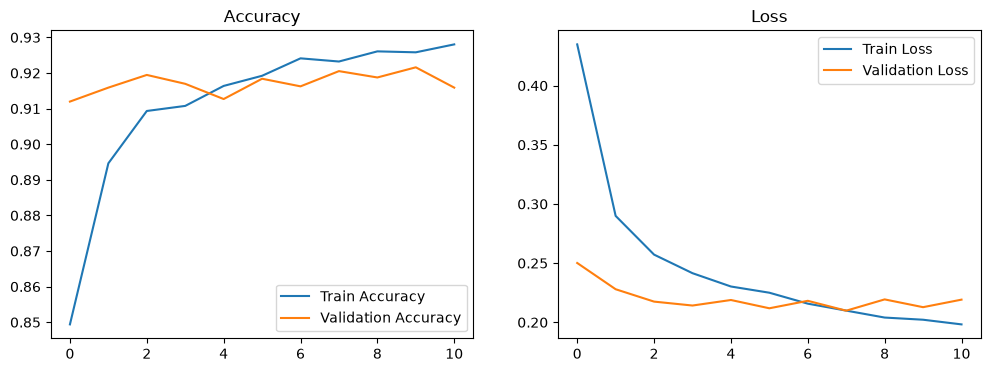

94/94 ━━━━━━━━━━━━━━━━━━━━ 13s 132ms/step

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

   buildings       0.95      0.92      0.93       437
      forest       1.00      0.99      0.99       474
     glacier       0.87      0.87      0.87       553
    mountain       0.88      0.87      0.87       525
         sea       0.94      0.97      0.96       510
      street       0.93      0.95      0.94       501

    accuracy                           0.93      3000
   macro avg       0.93      0.93      0.93      3000
weighted avg       0.93      0.93      0.93      3000



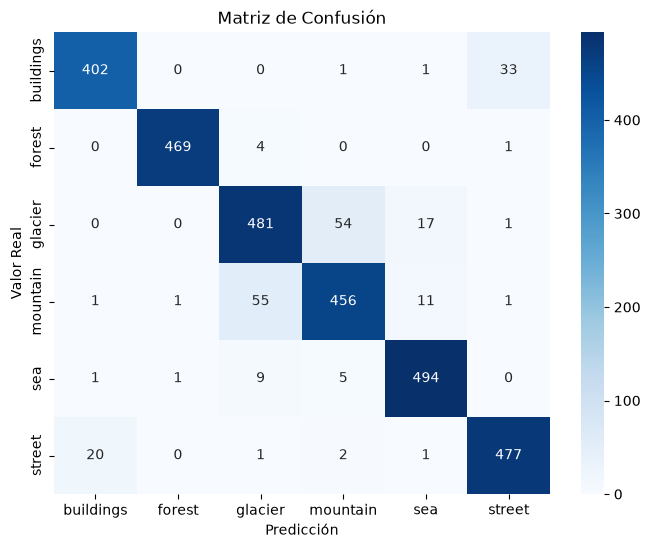

In [11]:
# Función para graficar Pérdida y Accuracy[cite: 9]
def plot_history(history):
    plt.figure(figsize=(12, 4))
    # Gráfica de Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Accuracy')
    plt.legend()
    # Gráfica de Pérdida (Loss)
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss')
    plt.legend()
    plt.show()

plot_history(historia)

# Generamos predicciones sobre el conjunto de prueba (seg_test)
y_pred_probs = modelo.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1) # Tomamos la clase con mayor probabilidad

# Extraemos las etiquetas reales del dataset de prueba
y_true = np.concatenate([y for x, y in test_ds], axis=0)

# Imprimimos Métricas: Accuracy, F1-Score, Precision, Recall[cite: 9]
print("\n--- Reporte de Clasificación ---")
print(classification_report(y_true, y_pred, target_names=clases))

# Matriz de Confusión[cite: 9]
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=clases, yticklabels=clases)
plt.title('Matriz de Confusión')
plt.ylabel('Valor Real')
plt.xlabel('Predicción')
plt.show()

# =====================================================================
# 6. EXPORTACIÓN PARA PRODUCCIÓN (Paso 2 de la Guía)
# =====================================================================

In [12]:
# Guardamos el modelo en formato .keras[cite: 2]
modelo.save("modelo.keras")

# Guardamos los nombres de las clases en un archivo JSON
with open("clases.json", "w", encoding="utf-8") as f:
    json.dump(clases, f, ensure_ascii=False)

print("¡Modelo y clases exportados con éxito!")

¡Modelo y clases exportados con éxito!
